In [15]:
import math
import numpy as np  
import matplotlib.pyplot as plt

In [5]:
def calculate_path_length(elevation_angle_degrees, height):
    elevation_angle_radians = math.radians(elevation_angle_degrees)
    path_length = height / math.sin(elevation_angle_radians)
    return path_length

In [6]:
pathlength = calculate_path_length(30, 2.5)
print(f"Path length through the rain: {pathlength:.2f} km")

Path length through the rain: 5.00 km


In [7]:
path_attenuation = pathlength * 1.5
print(f"Path attenuation for a specific attenuation of 1.5 dB/km: {path_attenuation:.2f} dB")

Path attenuation for a specific attenuation of 1.5 dB/km: 7.50 dB


In [10]:
radius_earth_m = 6371e3 # meters
leo_satellite_altitude_m = 1000e3 # meters 
f_hz = 1.5e9  # Hz
c = 3e8 # m/s
keplers_constant = 3.896e14 # m^3/s^2

def satellite_v(altitude_m):
   return np.sqrt(keplers_constant / ((radius_earth_m + altitude_m))) # sqrt( m^3/s^2 / m ) = sqrt( m^2/s^2 ) = m/s

def doppler_f_khz(altitude_km, f_khz, elevation_angle_deg=20.07):
    altitude_m = altitude_km * 1e3  # m
    v = satellite_v(altitude_m) # m/s
    elevation_angle_rad = np.radians(elevation_angle_deg)
    return (v*radius_earth_m*f_khz*np.cos(elevation_angle_rad)) / (c*(radius_earth_m + altitude_m))  # (m/s * m * s^-1) / (m/s * m)) = (m^2/s^2) / (m^2/s) = 1/s = kHz

In [12]:
L_band_khz = 1.25 * 1e6
X_band_khz = 11.0 * 1e6
Ku_band_khz = 16.5 * 1e6

altitude_km = np.linspace(0, 40000, 4000)
doppler_f_shift_L = doppler_f_khz(altitude_km, L_band_khz)
doppler_f_shift_X = doppler_f_khz(altitude_km, X_band_khz)
doppler_f_shift_Ku = doppler_f_khz(altitude_km, Ku_band_khz)

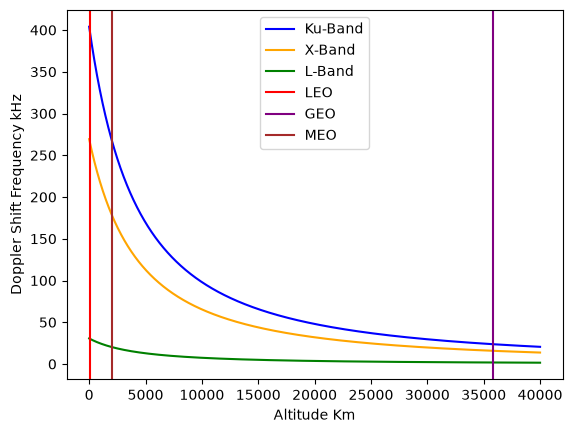

In [17]:
plt.plot(altitude_km, doppler_f_shift_Ku, label='Ku-Band', color='blue')
plt.plot(altitude_km, doppler_f_shift_X, label='X-Band', color='orange')
plt.plot(altitude_km, doppler_f_shift_L, label='L-Band', color='green')
plt.axvline(x=106, label="LEO", color='red')
plt.axvline(x=35786, label="GEO", color='purple')
plt.axvline(x=2000, label="MEO", color='brown')

plt.xlabel('Altitude Km')
plt.ylabel('Doppler Shift Frequency kHz')
plt.legend()  # Displays the labels assigned above